# CCEP baseline expansion

All 117 ds004080 runs screened under the frozen pilot preprocessing. One 32-second clean interval is sufficient; up to three per run. [Protocol and exclusions](../notes/ccep-cohort-261014.md). Participants are the independent units.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').is_file() and (p/'research/empirical/ccep_pilot').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from research.empirical.ccep_pilot.plots import style, save, cleaning_examples
RUN=ROOT/'results/ccep-cohort-261014'
CONFIG=ROOT/'research/empirical/ccep_pilot/configs'
reports=json.loads((RUN/'scope/runs.json').read_text())
review=json.loads((CONFIG/'cohort-review.json').read_text())
screen=json.loads((CONFIG/'cohort-screen.json').read_text())
rows=[]
for r in reports:
    decisions=review['runs'][r['run_id']]
    rows.append(dict(participant=r['subject'][-2:],run=r['run_id'].split('run-')[-1],M=r['M'],native_Hz=r['native_fs'],
                     before_stimulation_s=round(r['first_stimulation'],1),retained=sum(v['accept'] for v in decisions.values()),
                     candidate=len(r['windows']),duplicate=r['run_id'] in review['duplicate_of']))
dimensions=pd.DataFrame(rows)
display(pd.DataFrame({'quantity':['Runs screened','Metadata candidates','Unique represented runs including pilot','Independent participants','New CAR windows','New reference controls','Pilot tables reused'],
                      'n':[len(screen),sum(bool(r['starts']) for r in screen),34,24,int(dimensions.retained.sum()),int((dimensions.retained>0).sum()),19]}))

,quantity,n
0,Runs screened,117
1,Metadata candidates,35
2,Unique represented runs including pilot,34
3,Independent participants,24
4,New CAR windows,54
5,New reference controls,29
6,Pilot tables reused,19


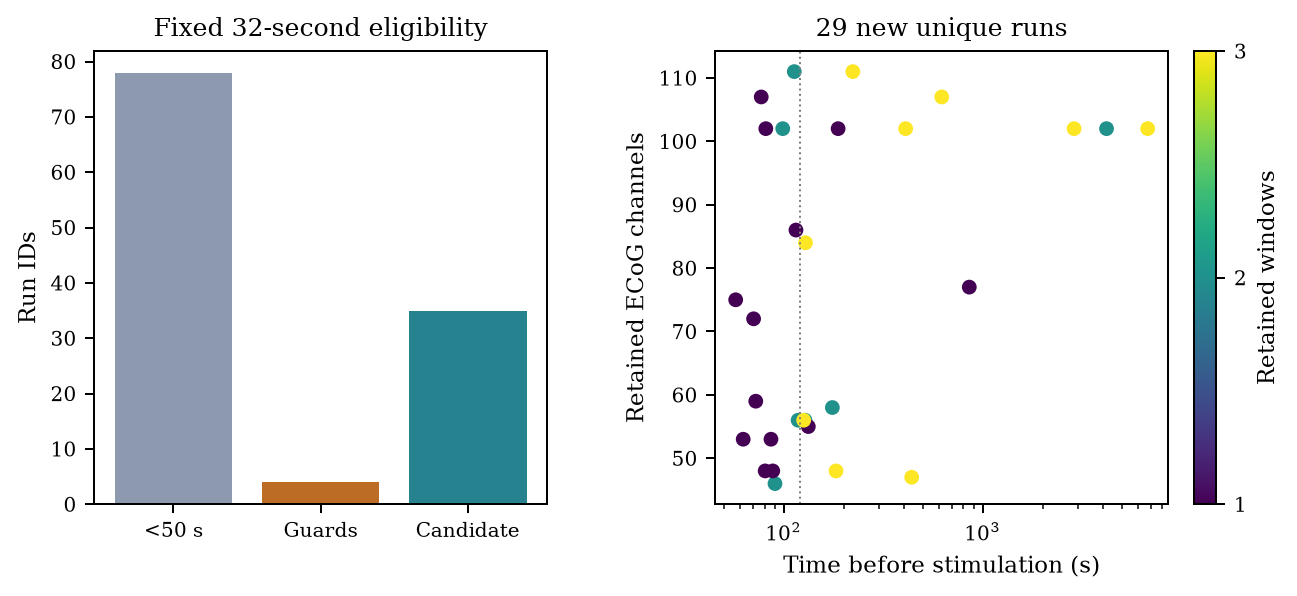

,participant,run,M,native_Hz,before_stimulation_s,retained,candidate,duplicate
0,01,021448,102,512,2877.9,3,3,False
1,01,031422,102,512,409.8,3,3,False
2,01,041224,102,512,4189.3,2,3,False
3,01,041550,102,512,6745.0,3,3,False
4,01,041750,102,512,187.5,1,2,False
5,01,061233,102,2048,98.8,2,2,False
6,01,061343,102,2048,81.2,1,1,False
7,02,021804,86,2048,115.1,1,2,False
8,03,031411,72,2048,70.5,1,1,False
9,04,031148,111,2048,112.9,2,2,False


In [2]:
plt=style()
fig,axes=plt.subplots(1,2,figsize=(7.2,3.2))
axes[0].bar(['<50 s','Guards','Candidate'],[78,4,35],color=['#8d99ae','#bc6c25','#26828e'])
axes[0].set(ylabel='Run IDs',title='Fixed 32-second eligibility')
active=dimensions[~dimensions.duplicate]
sc=axes[1].scatter(active.before_stimulation_s,active.M,c=active.retained,vmin=1,vmax=3,cmap='viridis',s=24)
axes[1].set(xscale='log',xlabel='Time before stimulation (s)',ylabel='Retained ECoG channels',title='29 new unique runs')
axes[1].axvline(120,color='.5',ls=':',lw=.8)
fig.colorbar(sc,ax=axes[1],ticks=[1,2,3],label='Retained windows')
for ax in axes: ax.set_box_aspect(1)
save(fig,RUN/'figures','cohort-scope')
display(Image(filename=str(RUN/'figures/cohort-scope.png')))
display(dimensions)

All 63 new candidate windows passed numerical QC; native review excluded seven. Below: a slow excursion, a few-sample discontinuity, and resolved sharp activity retained with a flag. Heatmaps show every channel across the full 32 s; native traces reveal details filtering/downsampling can obscure. Colour limits ±3 are **display saturation**, not signal clipping or cleaning. Window labels are zero-based.

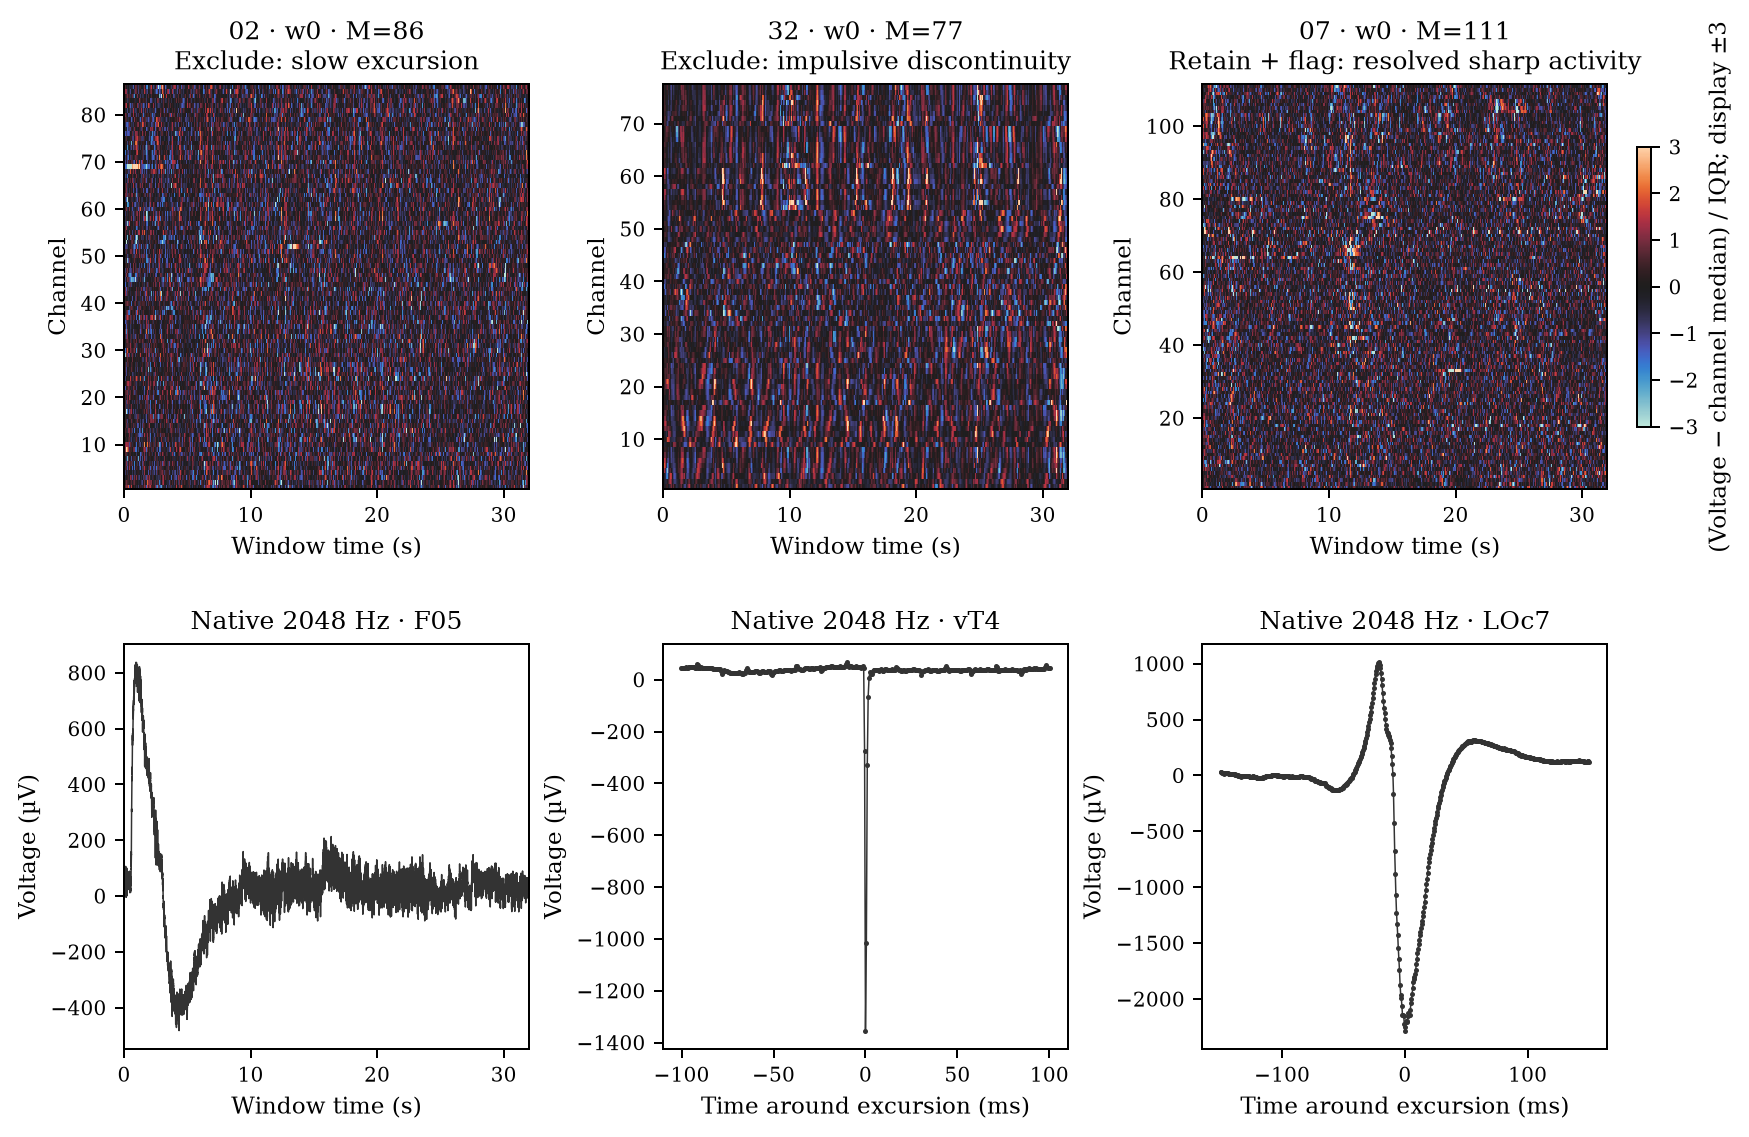

In [3]:
cleaning_examples(RUN, CONFIG/'cohort-review.json')
display(Image(filename=str(RUN/'figures/cleaning-decisions.png')))

Cleaning selects intervals and declared-good ECoG contacts; rejected transients are not interpolated away. Participant02 w0 is excluded, while the later w1 below is retained. Both heatmaps use per-channel median/IQR scaling; the reference changes, the interval does not. CAR subtracts the retained-channel mean; filtering retains 0.5–45 Hz before polyphase resampling to 128 Hz. Four-second filter pads are discarded; final input is channel-z-scored, M×4096. Native response data remain unchanged.

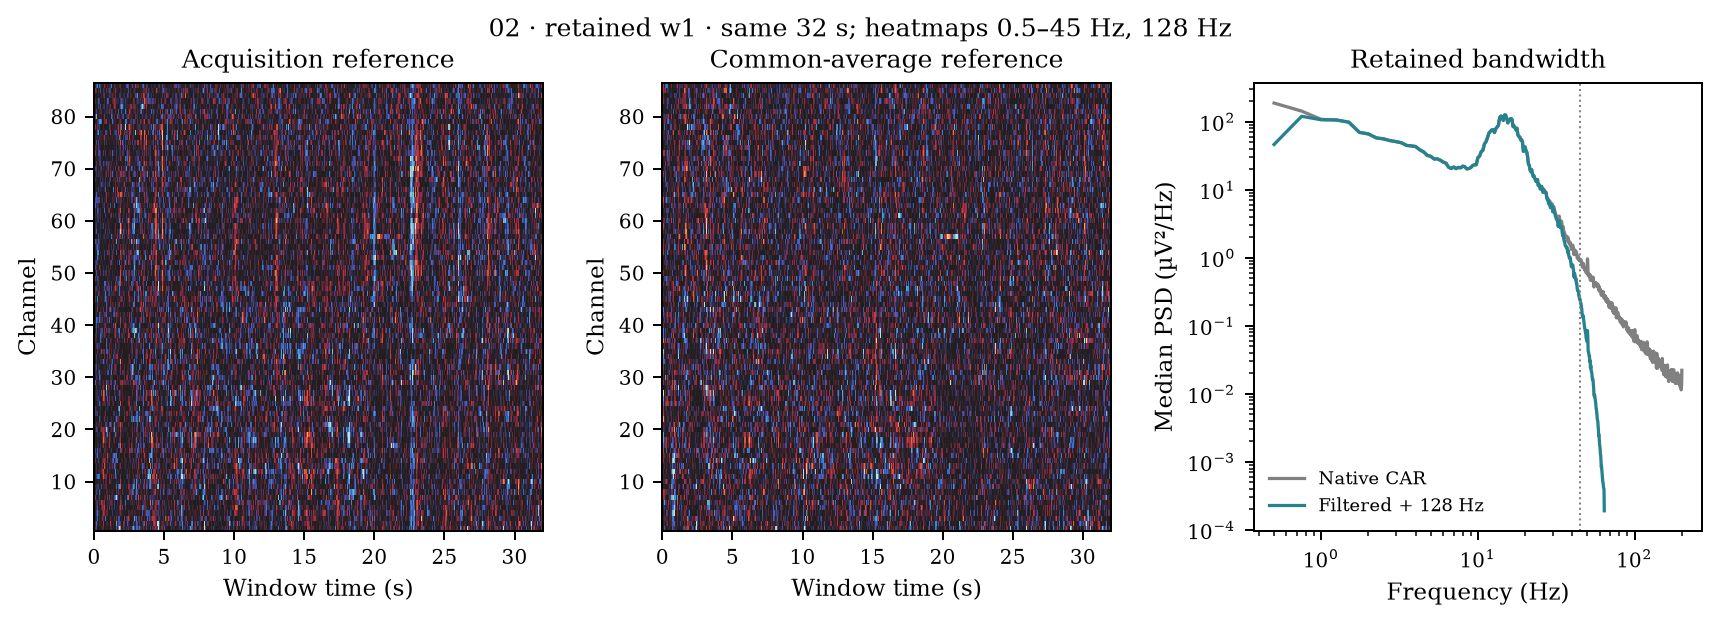

,participant,window,start_s,end_s,first_pulse_s,retain
0,02,0,9.00,41.00,115.07,False
1,02,1,57.28,89.28,115.07,True
2,32,0,9.00,41.00,855.67,False
3,32,1,53.11,85.11,855.67,False
4,32,2,97.22,129.22,855.67,True
5,07,0,9.00,41.00,222.32,True
6,07,1,77.93,109.93,222.32,True
7,07,2,181.32,213.32,222.32,True


In [4]:
display(Image(filename=str(RUN/'figures/cleaning-reference-bandwidth.png')))
examples=[]
for subject,run in [('02','021804'),('32','031446'),('07','021647')]:
    key=f'sub-ccepAgeUMCU{subject}_ses-1_task-SPESclin_run-{run}'
    report=json.loads((RUN/'scope'/f'{key}.json').read_text())
    for w in report['windows']:
        examples.append(dict(participant=subject,window=w['window'],start_s=round(w['start'],2),end_s=round(w['start']+32,2),first_pulse_s=round(report['first_stimulation'],2),retain=review['runs'][key][str(w['window'])]['accept']))
display(pd.DataFrame(examples))

All **102/102 tables validate**: 83 cohort plus 19 pilot; exact fd0de71/r9 source, input hashes, catalogue and ≥90% finite-edge coverage. Full edges, QC and sampling remain frozen. The fixed-axis transfer below replays both constituent SPI matrices from every prepared recording.

Participant56/run021112 is an exact duplicate of run011112, computed once. Final expansion: **29 unique runs, 54 CAR windows + 29 reference controls = 83 tables**. With the original pilot: 34 unique runs, 24 participants, 102 tables. [Investigation and fixed latency test](../notes/ccep-pilot-261014.md#investigation-and-one-latency-test).

## Fixed lag/spectral axis: independent extension

Keep the pilot coordinate, **Pearson zero lag × symmetric Pearson 31.25 ms lag**, and the **8–24 Hz** Fourier ablation fixed. Analyse 19 new participants separately from the original five. Summaries take the median across windows within each run, then across runs within each participant; matched reference comparisons use the same first retained interval. No PCA refit or outcome-driven feature search.

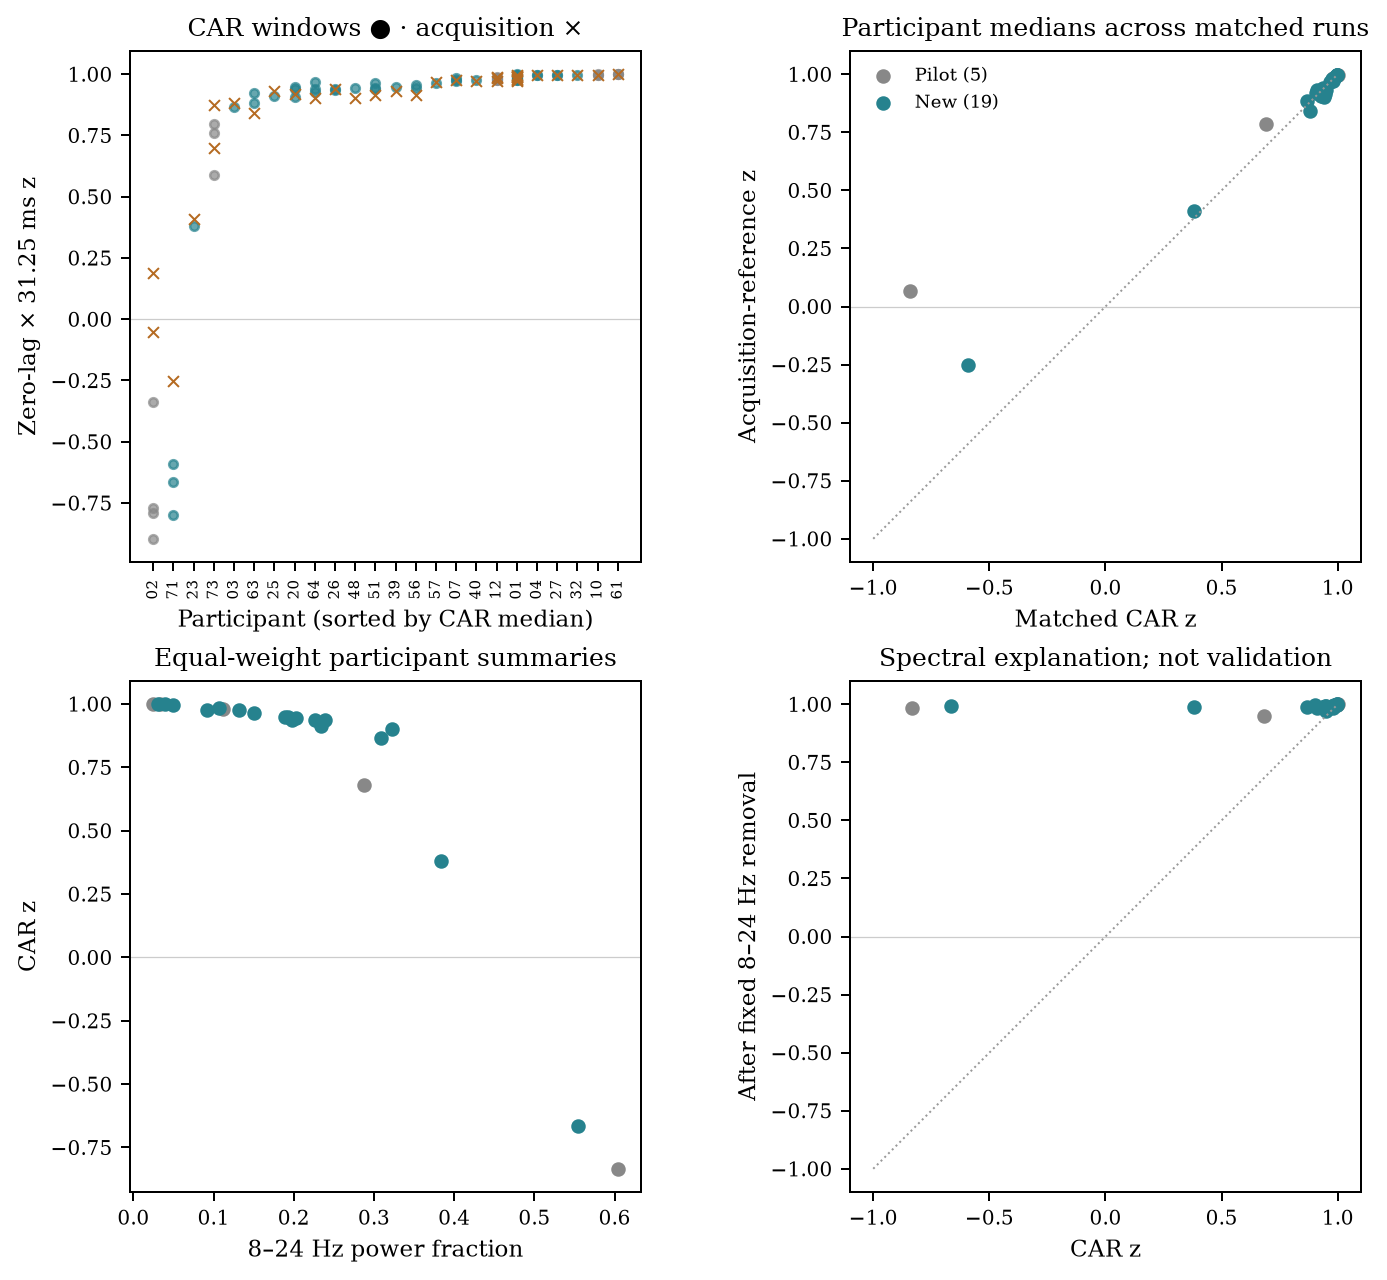

In [5]:
from research.empirical.ccep_pilot.cohort_interpret import main as interpret_cohort
summary=interpret_cohort(ROOT/'results/ccep-pilot-261014', RUN)
display(Image(filename=str(RUN/'figures/cohort-character-transfer.png')))

The independent extension reproduces the continuum: participant-median z versus 8–24 Hz channel-standardised power fraction has Spearman ρ=−.968 (leave-one-participant-out −.986 to −.963). At 31.25 ms, this band lies in a negative cosine lobe of the cross-spectral lag weighting. Full cross-spectrum replay reproduces all 102 z within .00188. This is a spectral explanation of edge-profile reorganisation, not independent physiological validation or a conduction-delay estimate.

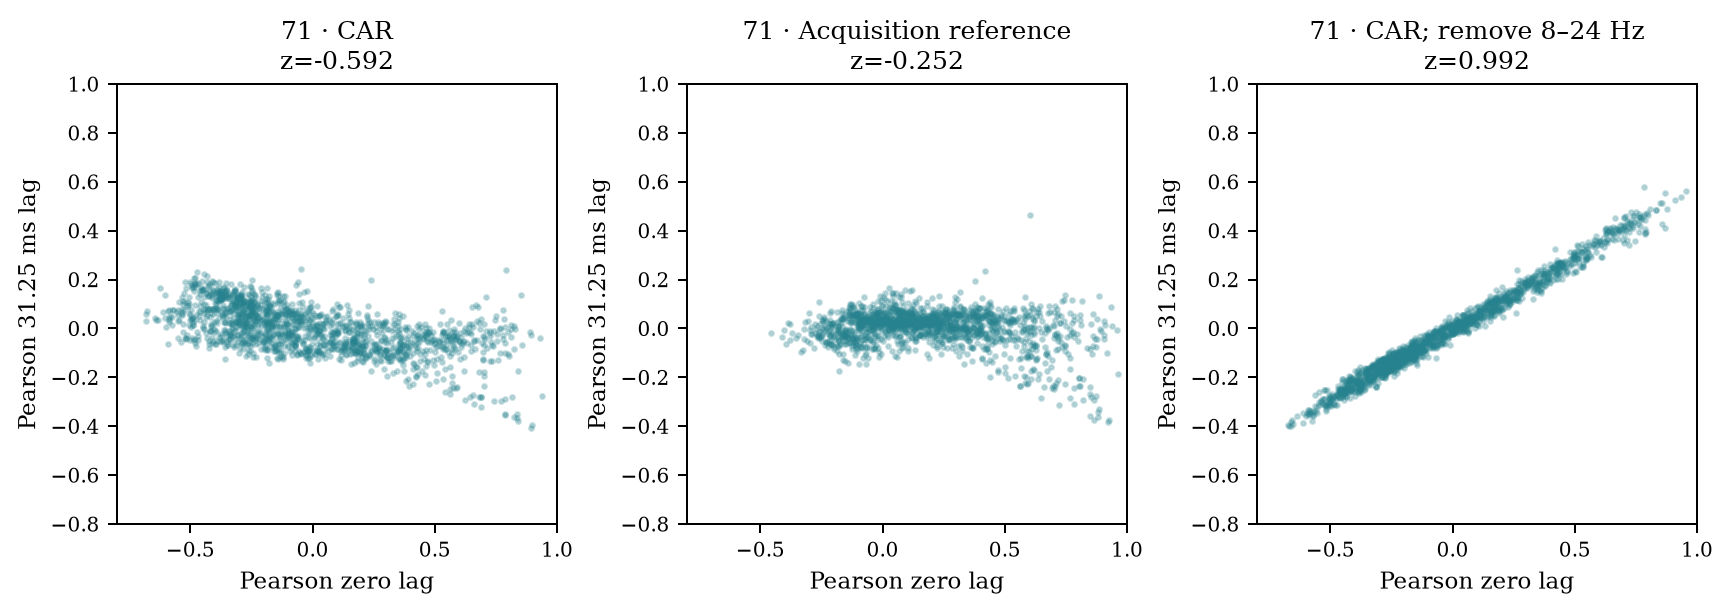

,window,reference_control,z,z_ablated,band_fraction,delete_min,delete_max
96,0,False,-0.592,0.992,0.554,-0.612,-0.567
97,1,False,-0.800,0.993,0.591,-0.813,-0.788
98,2,False,-0.666,0.993,0.547,-0.685,-0.645
99,0,True,-0.252,0.991,0.512,-0.304,-0.206


In [6]:
display(Image(filename=str(RUN/'figures/cohort-transfer-edges.png')))
axis=pd.read_csv(RUN/'interpretation/character-axis.csv')
display(axis[axis.subject.str.endswith('71')][['window','reference_control','z','z_ablated','band_fraction','delete_min','delete_max']].round(3))

Participant71 (M=56; illustrated because it has the lowest new-participant median z) replicates the negative signature in all three windows: −.592, −.800, −.666; the matched acquisition-reference value is −.252. Fixed-band removal gives +.992 to +.993. Participant23 supplies an intermediate value (+.382 → +.989 after ablation). Single-channel deletion preserves the sign of every CAR window. Participant71 had recurrent sharp/bursty activity flagged during frozen QC; replication therefore concerns the retained signal phenotype, without assigning a clinical or neuronal mechanism.

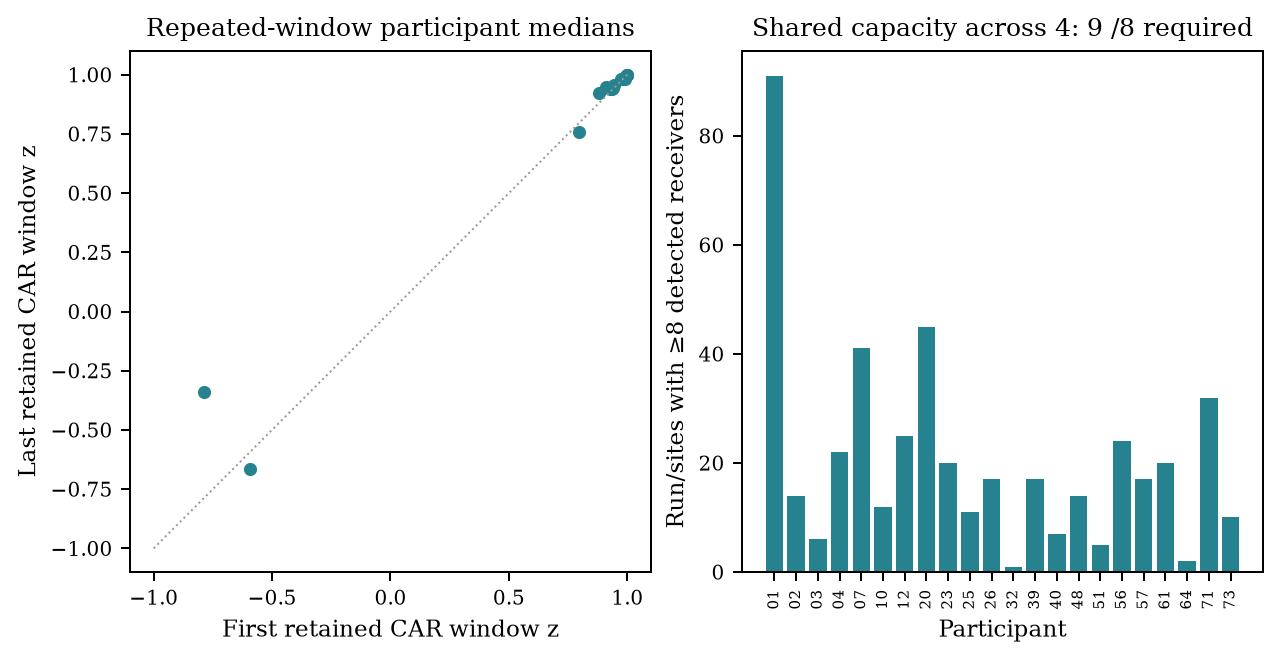

,all,new
participants,24.000,19.000
repeated_window_participants,16.000,11.000
window_spearman,0.976,0.945
median_within_run_span,0.012,0.013
reference_spearman,0.954,0.909
median_absolute_reference_change,0.014,0.017
max_absolute_reference_change,0.909,0.340


In [7]:
display(Image(filename=str(RUN/'figures/cohort-window-n1-support.png')))
metrics=['participants','repeated_window_participants','window_spearman','median_within_run_span','reference_spearman','median_absolute_reference_change','max_absolute_reference_change']
display(pd.DataFrame({group:{k:summary[group][k] for k in metrics} for group in ['all','new']}).round(3))

Among the 19 new participants, matched-reference ranks agree (ρ=.909; median |Δz|=.017; largest .340 in participant71). All 19 participant summaries retain their sign. Eleven new participants have repeated windows: first/last ranks agree (ρ=.945); median within-run span=.013, maximum=.208; all 15 repeated runs retain their sign. Eight new participants have no repeated-window estimate. These are descriptive sensitivity summaries, not independent-window significance tests or proof of a stationary fingerprint. Original participant02 remains substantially reference-sensitive.

## Matched N1 feasibility

Published native-time N1 derivatives match all **34 runs / 24 participants** with frozen contact, pulse, artefact and seizure exclusions: 7,689 detected responses. There are 453 run/sites with ≥8 detected receivers across 22 participants. Exact Destrieux × 20 mm stimulation-distance support now retains **eight receivers in at most five distinct participants** (02/20/39/51/61 is one coverage-only choice); no six-person combination meets it. A four-person combination has capacity nine. Repeated runs cannot supply independent participants. Seven receiver/site rows lack exact electrode-name matches and are excluded from anatomical matching without guessing aliases.

In [8]:
gate=summary['n1']
display(pd.DataFrame(gate['witness']))
geometry=pd.read_csv(RUN/'interpretation/n1-matched-geometry.csv')
display(geometry.groupby('subject').pair_distance_median_mm.agg(['min','median','max']).round(1))
display(pd.DataFrame(gate['shared_strata']))

,subject,run,site
0,sub-ccepAgeUMCU02,sub-ccepAgeUMCU02_ses-1_task-SPESclin_run-0218...,FC21-FC22
1,sub-ccepAgeUMCU20,sub-ccepAgeUMCU20_ses-1_task-SPESclin_run-0116...,F29-F30
2,sub-ccepAgeUMCU39,sub-ccepAgeUMCU39_ses-1_task-SPESclin_run-0213...,F06-F07
3,sub-ccepAgeUMCU51,sub-ccepAgeUMCU51_ses-1_task-SPESclin_run-0309...,C38-C39
4,sub-ccepAgeUMCU61,sub-ccepAgeUMCU61_ses-1_task-SPESclin_run-0212...,P11-P12


,min,median,max
subject,,,
sub-ccepAgeUMCU02,25.3,28.9,31.8
sub-ccepAgeUMCU20,20.1,23.0,24.3
sub-ccepAgeUMCU39,26.2,26.5,26.5
sub-ccepAgeUMCU51,28.6,28.6,28.6
sub-ccepAgeUMCU61,24.9,25.6,27.3


,label,distance_bin_mm,count
0,G&S_subcentral,"[20, 40]",1
1,G_front_middle,"[20, 40]",1
2,G_postcentral,"[0, 20]",1
3,G_postcentral,"[20, 40]",1
4,G_precentral,"[0, 20]",3
5,G_precentral,"[20, 40]",1


The five-person witness is mainly perirolandic, with four of eight receivers precentral. Its anatomy/stimulation-distance matched resamples still have typical receiver-pair median distances of 23–29 mm; they are not yet matched on receiver-pair geometry. **A small matched feasibility test is now possible; a cohort-wide controlled N1 claim is not.** Before any association, complete the already specified short-lag calibration and fix a receiver-pair distance balance criterion without inspecting N1 associations. The N1 candidate remains the separately defined z_short, not a relabelling of this spectral coordinate. No z–latency association was run; the explicit support search and 256 seed-261014 contact resamples use coverage only.